# 04. Обучение и оценка моделей

**Цель:** сравнить три модели бинарной классификации, выбрать итоговую по кросс-валидации и один раз оценить её на тестовой выборке.

Сравниваю:

1. Logistic Regression — интерпретируемая базовая модель.
2. Decision Tree — дерево решений.
3. Random Forest — ансамбль деревьев.

Основная метрика выбора — **PR-AUC**: она лучше подходит для несбалансированных классов, когда важен положительный класс (ушедшие клиенты). Дополнительно смотрю ROC-AUC, Precision, Recall и F1-score.

Порог классификации выбираю по out-of-fold предсказаниям на тренировочной выборке. Тестовая выборка не используется для подбора порога.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv", usecols=["Churn"]).squeeze("columns")
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv", usecols=["Churn"]).squeeze("columns")

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Доля оттока в train:", round(y_train.mean(), 4))
print("Доля оттока в test:", round(y_test.mean(), 4))

Train: (5634, 19)
Test: (1409, 19)
Доля оттока в train: 0.2654
Доля оттока в test: 0.2654


## 1. Модели и сетка гиперпараметров

In [3]:
numeric_features = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [
    column for column in X_train.columns if column not in numeric_features
]


def build_preprocessor():
    # Препроцессинг создаётся заново, чтобы обучаться внутри каждого фолда.
    numeric_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]
    )
    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="ignore",
                    drop="if_binary",
                    sparse_output=False,
                ),
            ),
        ]
    )

    return ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, numeric_features),
            ("cat", categorical_transformer, categorical_features),
        ]
    )


def build_pipeline(estimator):
    return Pipeline(
        steps=[
            ("preprocessor", build_preprocessor()),
            ("model", estimator),
        ]
    )


models = {
    "Logistic Regression": (
        build_pipeline(
            LogisticRegression(
                max_iter=2000,
                solver="liblinear",
                random_state=RANDOM_STATE,
            )
        ),
        {
            "model__C": [0.01, 0.1, 1.0, 10.0],
            "model__class_weight": [None, "balanced"],
        },
    ),
    "Decision Tree": (
        build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        {
            "model__max_depth": [3, 5, 7, 10, None],
            "model__min_samples_leaf": [1, 5, 10, 20],
            "model__class_weight": [None, "balanced"],
        },
    ),
    "Random Forest": (
        build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)),
        {
            "model__n_estimators": [200, 400],
            "model__max_depth": [5, 10, None],
            "model__min_samples_leaf": [1, 5, 10],
            "model__class_weight": [None, "balanced"],
        },
    ),
}

## 2. Подбор гиперпараметров по кросс-валидации

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
searches = {}

for model_name, (pipeline, param_grid) in models.items():
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        refit=True,
    )
    search.fit(X_train, y_train)
    searches[model_name] = search

    print(f"{model_name}:")
    print(f"  лучший PR-AUC на CV: {search.best_score_:.4f}")
    print(f"  параметры: {search.best_params_}")

Logistic Regression:
  лучший PR-AUC на CV: 0.6615
  параметры: {'model__C': 1.0, 'model__class_weight': None}


Decision Tree:
  лучший PR-AUC на CV: 0.6201
  параметры: {'model__class_weight': 'balanced', 'model__max_depth': 7, 'model__min_samples_leaf': 20}


Random Forest:
  лучший PR-AUC на CV: 0.6629
  параметры: {'model__class_weight': None, 'model__max_depth': 10, 'model__min_samples_leaf': 10, 'model__n_estimators': 200}


In [5]:
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

cv_rows = []
for model_name, search in searches.items():
    scores = cross_validate(
        search.best_estimator_,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )
    cv_rows.append(
        {
            "Модель": model_name,
            "CV ROC-AUC": scores["test_roc_auc"].mean(),
            "CV PR-AUC": scores["test_pr_auc"].mean(),
            "CV Precision": scores["test_precision"].mean(),
            "CV Recall": scores["test_recall"].mean(),
            "CV F1": scores["test_f1"].mean(),
        }
    )

cv_results = pd.DataFrame(cv_rows).set_index("Модель").round(4)
cv_results

,CV ROC-AUC,CV PR-AUC,CV Precision,CV Recall,CV F1
Модель,,,,,
Logistic Regression,0.8461,0.6615,0.6530,0.5445,0.5932
Decision Tree,0.8167,0.6201,0.5058,0.7793,0.6131
Random Forest,0.8474,0.6629,0.6718,0.5043,0.5757


## 3. Выбор итоговой модели и порога

In [6]:
best_model_name = cv_results["CV PR-AUC"].idxmax()
best_model = searches[best_model_name].best_estimator_

print("Итоговая модель:", best_model_name)

Итоговая модель: Random Forest


In [7]:
oof_probabilities = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_train, oof_probabilities)
f1_scores = np.divide(
    2 * precision[:-1] * recall[:-1],
    precision[:-1] + recall[:-1],
    out=np.zeros_like(precision[:-1]),
    where=(precision[:-1] + recall[:-1]) > 0,
)

threshold_table = pd.DataFrame(
    {
        "threshold": thresholds,
        "precision": precision[:-1],
        "recall": recall[:-1],
        "f1": f1_scores,
    }
)

# Бизнес-правило: не пропускать больше 20% ушедших клиентов.
candidates = threshold_table[threshold_table["recall"] >= 0.80]
best_threshold = (
    float(candidates.loc[candidates["precision"].idxmax(), "threshold"])
    if not candidates.empty
    else 0.5
)

print(f"Выбранный порог: {best_threshold:.4f}")
threshold_table[
    (threshold_table["threshold"] - best_threshold).abs() < 0.02
].round(4)

Выбранный порог: 0.2781


,threshold,precision,recall,f1
3228,0.2582,0.5121,0.8207,0.6307
3229,0.2583,0.5123,0.8207,0.6308
3230,0.2585,0.5125,0.8207,0.6310
3231,0.2585,0.5123,0.8201,0.6307
3232,0.2586,0.5121,0.8194,0.6303
...,...,...,...,...
3457,0.2973,0.5379,0.7793,0.6364
3458,0.2976,0.5381,0.7793,0.6366
3459,0.2977,0.5384,0.7793,0.6368
3460,0.2979,0.5386,0.7793,0.6370


In [8]:
oof_predictions = (oof_probabilities >= best_threshold).astype(int)

print(
    classification_report(
        y_train,
        oof_predictions,
        target_names=["Остался", "Ушёл"],
        digits=4,
    )
)

              precision    recall  f1-score   support

     Остался     0.9107    0.7371    0.8148      4139
        Ушёл     0.5236    0.8000    0.6330      1495

    accuracy                         0.7538      5634
   macro avg     0.7172    0.7686    0.7239      5634
weighted avg     0.8080    0.7538    0.7665      5634



## 4. Финальная оценка на тестовой выборке

In [9]:
def evaluate_model(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions),
        "recall": recall_score(y_true, predictions),
        "f1": f1_score(y_true, predictions),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities),
    }


test_rows = []
for model_name, search in searches.items():
    probabilities = search.predict_proba(X_test)[:, 1]
    row = evaluate_model(y_test, probabilities, 0.5)
    row["Модель"] = model_name
    test_rows.append(row)

test_results = pd.DataFrame(test_rows).set_index("Модель").round(4)
test_results

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
Модель,,,,,,,
Logistic Regression,0.5,0.8055,0.6562,0.5615,0.6052,0.8421,0.6345
Decision Tree,0.5,0.7324,0.4975,0.7995,0.6133,0.8251,0.6254
Random Forest,0.5,0.8027,0.6644,0.5187,0.5826,0.8425,0.6548


In [10]:
best_model.fit(X_train, y_train)
test_probabilities = best_model.predict_proba(X_test)[:, 1]
final_predictions = (test_probabilities >= best_threshold).astype(int)

final_test_metrics = evaluate_model(y_test, test_probabilities, best_threshold)
pd.DataFrame([final_test_metrics], index=[best_model_name]).round(4)

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
Random Forest,0.2781,0.7495,0.5183,0.7941,0.6272,0.8425,0.6548


In [11]:
threshold_comparison = pd.DataFrame(
    [
        {"Порог": 0.5, **evaluate_model(y_test, test_probabilities, 0.5)},
        {"Порог": round(best_threshold, 4), **final_test_metrics},
    ]
).set_index("Порог")

threshold_comparison.round(4)

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
Порог,,,,,,,
0.5000,0.5000,0.8027,0.6644,0.5187,0.5826,0.8425,0.6548
0.2781,0.2781,0.7495,0.5183,0.7941,0.6272,0.8425,0.6548


In [12]:
cv_results.to_csv(REPORTS_DIR / "cv_metrics.csv")
test_results.to_csv(REPORTS_DIR / "model_metrics.csv")

print("Сохранено:", REPORTS_DIR / "cv_metrics.csv")
print("Сохранено:", REPORTS_DIR / "model_metrics.csv")

Сохранено: C:\Users\rrr9g\OneDrive\Рабочий стол\Projects\project1\reports\cv_metrics.csv
Сохранено: C:\Users\rrr9g\OneDrive\Рабочий стол\Projects\project1\reports\model_metrics.csv


## 5. Матрицы ошибок

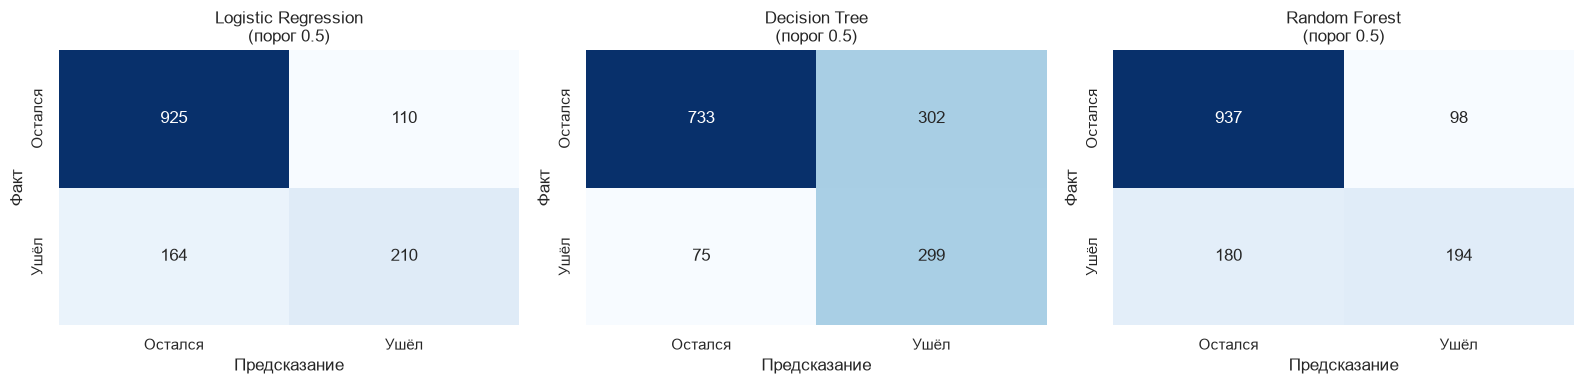

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (model_name, search) in zip(axes, searches.items()):
    predictions = search.predict(X_test)
    matrix = confusion_matrix(y_test, predictions)

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Остался", "Ушёл"],
        yticklabels=["Остался", "Ушёл"],
        ax=ax,
    )
    ax.set_title(f"{model_name}\n(порог 0.5)")
    ax.set_xlabel("Предсказание")
    ax.set_ylabel("Факт")

plt.tight_layout()
plt.show()

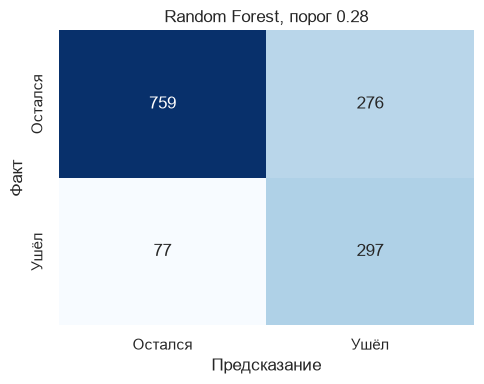

In [14]:
final_matrix = confusion_matrix(y_test, final_predictions)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    final_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Остался", "Ушёл"],
    yticklabels=["Остался", "Ушёл"],
    ax=ax,
)
ax.set_title(f"{best_model_name}, порог {best_threshold:.2f}")
ax.set_xlabel("Предсказание")
ax.set_ylabel("Факт")

plt.tight_layout()
plt.show()

## 6. ROC- и PR-кривые

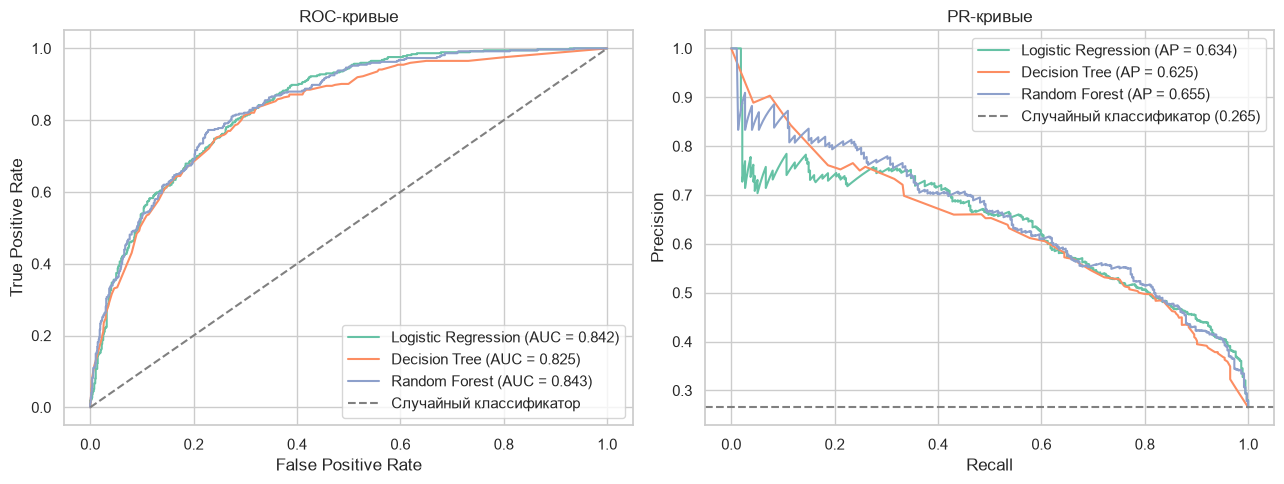

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for model_name, search in searches.items():
    probabilities = search.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, probabilities)
    axes[0].plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_auc_score(y_test, probabilities):.3f})",
    )

    curve_precision, curve_recall, _ = precision_recall_curve(y_test, probabilities)
    axes[1].plot(
        curve_recall,
        curve_precision,
        label=f"{model_name} (AP = {average_precision_score(y_test, probabilities):.3f})",
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Случайный классификатор")
axes[0].set_title("ROC-кривые")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

axes[1].axhline(
    y_test.mean(),
    linestyle="--",
    color="gray",
    label=f"Случайный классификатор ({y_test.mean():.3f})",
)
axes[1].set_title("PR-кривые")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Интерпретация модели

In [16]:
def get_feature_importance(model, top_n=15):
    preprocessor = model.named_steps["preprocessor"]
    estimator = model.named_steps["model"]
    feature_names = [name.split("__", 1)[1] for name in preprocessor.get_feature_names_out()]

    if hasattr(estimator, "coef_"):
        values = pd.Series(estimator.coef_[0], index=feature_names, name="importance")
        values = values.reindex(values.abs().sort_values(ascending=False).index)
    else:
        values = pd.Series(
            estimator.feature_importances_,
            index=feature_names,
            name="importance",
        ).sort_values(ascending=False)

    return values.head(top_n)


importance = get_feature_importance(best_model)
importance

Contract_Month-to-month           0.143646
tenure                            0.139165
TotalCharges                      0.114110
MonthlyCharges                    0.070405
TechSupport_No                    0.066112
OnlineSecurity_No                 0.063855
InternetService_Fiber optic       0.055817
PaymentMethod_Electronic check    0.049378
Contract_Two year                 0.035661
InternetService_DSL               0.023400
OnlineBackup_No                   0.020101
Contract_One year                 0.019781
OnlineSecurity_Yes                0.019314
DeviceProtection_No               0.016826
PaperlessBilling_Yes              0.014776
Name: importance, dtype: float64

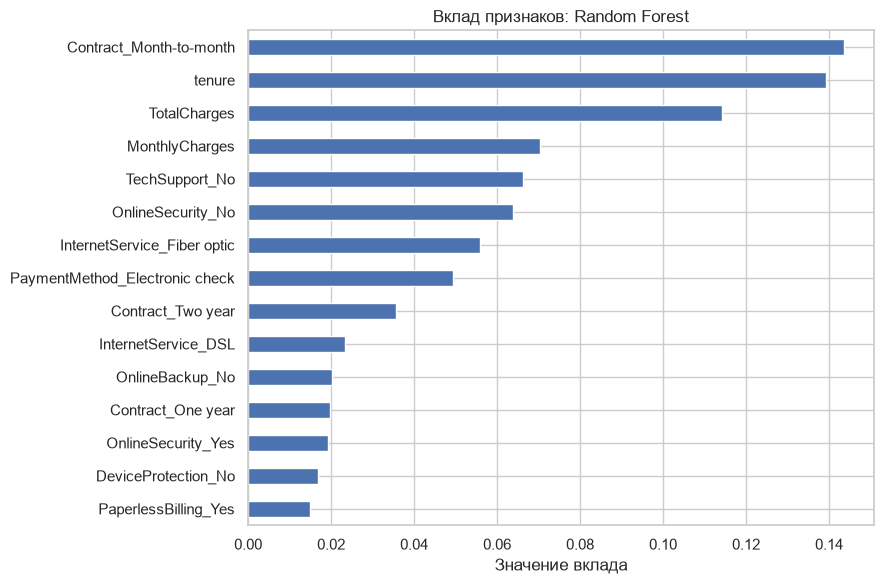

In [17]:
fig, ax = plt.subplots(figsize=(9, 6))
importance.sort_values().plot.barh(ax=ax, color="#4C72B0")

ax.set_title(f"Вклад признаков: {best_model_name}")
ax.set_xlabel("Значение вклада")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

Для логистической регрессии знак коэффициента показывает направление связи: положительное значение увеличивает оценку риска, отрицательное — уменьшает. Для деревьев важность показывает только силу вклада признака, но не направление.

Важность признака не доказывает причинно-следственную связь: признаки могут быть коррелированы между собой.

## 8. Бизнес-интерпретация

In [18]:
test_customer_ids = pd.read_csv(PROCESSED_DIR / "test_customer_ids.csv")["customerID"]

test_predictions = pd.DataFrame(
    {
        "customerID": test_customer_ids,
        "churn_probability": test_probabilities,
        "actual_churn": y_test.to_numpy(),
        "predicted_churn": final_predictions,
        "monthly_charges": X_test["MonthlyCharges"].to_numpy(),
        "contract": X_test["Contract"].to_numpy(),
    }
)

high_risk = test_predictions[test_predictions["predicted_churn"] == 1]

print(f"Клиентов в тесте: {len(test_predictions):,}")
print(
    f"В группе высокого риска: {len(high_risk):,} "
    f"({len(high_risk) / len(test_predictions):.1%})"
)
print(f"Доля реально ушедших в группе риска: {high_risk['actual_churn'].mean():.1%}")
print(
    f"Поймано ушедших: {int(high_risk['actual_churn'].sum())} "
    f"из {int(test_predictions['actual_churn'].sum())}"
)
print(f"Ежемесячные платежи группы риска: {high_risk['monthly_charges'].sum():,.0f}")

Клиентов в тесте: 1,409
В группе высокого риска: 573 (40.7%)
Доля реально ушедших в группе риска: 51.8%
Поймано ушедших: 297 из 374
Ежемесячные платежи группы риска: 42,234


In [19]:
top_n = max(1, int(len(test_predictions) * 0.10))
top_risk = test_predictions.nlargest(top_n, "churn_probability")

print(f"Топ-10% по вероятности оттока: {len(top_risk):,} клиентов")
print(f"Доля реально ушедших: {top_risk['actual_churn'].mean():.1%}")
print(f"Ежемесячные платежи: {top_risk['monthly_charges'].sum():,.0f}")

Топ-10% по вероятности оттока: 140 клиентов
Доля реально ушедших: 77.1%
Ежемесячные платежи: 11,310


In [20]:
high_risk_by_contract = (
    high_risk.groupby("contract")
    .agg(
        customers=("customerID", "count"),
        monthly_charges=("monthly_charges", "sum"),
        actual_churn_rate=("actual_churn", "mean"),
    )
    .assign(
        actual_churn_rate=lambda x: (x["actual_churn_rate"] * 100).round(2),
        monthly_charges=lambda x: x["monthly_charges"].round(2),
    )
    .sort_values("customers", ascending=False)
)
high_risk_by_contract

,customers,monthly_charges,actual_churn_rate
contract,,,
Month-to-month,559,40998.10,52.59
One year,14,1235.85,21.43


## 9. Сохранение модели

In [21]:
model_path = MODELS_DIR / "churn_model.joblib"
joblib.dump(best_model, model_path)

print("Модель сохранена:", model_path)
print("Размер файла:", f"{model_path.stat().st_size:,} байт")

Модель сохранена: C:\Users\rrr9g\OneDrive\Рабочий стол\Projects\project1\models\churn_model.joblib
Размер файла: 5,359,243 байт


## 10. Выводы

**Итоговая модель.** По кросс-валидации выбран **Random Forest** с параметрами `n_estimators=200`, `max_depth=10`, `min_samples_leaf=10`. Его CV PR-AUC — **0,6629**, CV ROC-AUC — **0,8474**. Logistic Regression отстаёт незначительно: PR-AUC **0,6615**, ROC-AUC **0,8461**, но выигрывает в интерпретируемости. Для реального внедрения этот компромисс стоит обсудить с бизнесом; в учебном проекте оставляю модель с лучшей CV-метрикой.

**Качество на тесте.** При пороге **0,2781**, выбранном по out-of-fold предсказаниям с требованием Recall ≥ 0,80:

- Accuracy — **0,7495**;
- Precision — **0,5183**;
- Recall — **0,7941**;
- F1-score — **0,6272**;
- ROC-AUC — **0,8425**;
- PR-AUC — **0,6548**.

При стандартном пороге 0,5 модель чаще ошибается в сторону пропуска ушедших: Recall падает до **0,5187**, но Precision растёт до **0,6644**. Выбор порога — это управленческий компромисс между стоимостью пропущенного клиента и стоимостью лишнего контакта.

**Интерпретация.** Наибольший вклад в решение Random Forest дают `Contract_Month-to-month`, `tenure`, `TotalCharges`, `MonthlyCharges`, отсутствие техподдержки и онлайн-защиты, оптоволоконный интернет и оплата через `Electronic check`. Это согласуется с выводами EDA, но важность признака не доказывает причинность.

**Бизнес-вывод.** В тестовой выборке модель отметила **573 клиента (40,7%)** как группу высокого риска. Среди них реально ушли **51,8%**, модель поймала **297 из 374** ушедших. Суммарные ежемесячные платежи этой группы — около **42 234**. Топ-10% клиентов по вероятности оттока дают **77,1%** фактического оттока при платежах около **11 310** в месяц. Это позволяет приоритизировать контакты, но не гарантирует, что удержание предотвратит уход.

**Ограничения.** Использовано одно разбиение train/test, без временной валидации; данных о стоимости контакта и эффективности удержания нет; порог Recall ≥ 0,80 — учебное допущение; важность признаков в Random Forest может быть смещена в сторону признаков с большим числом категорий. Результаты нельзя переносить на реальную компанию без дополнительной проверки.